# Robust Design Optimization: Trading Nominal Performance for Insensitivity

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Ahmed-Bayoumy/MECH559/blob/HEAD/L14/L14_robust_design_optimization.ipynb)
### MECH 559 - Systems Optimization - L14
### Course Instructor: Dr. Ahmed Bayoumy
Author of the notebook: Dr. Ahmed Bayoumy

Companion notebook to the "Robust design optimization (RDO)" slides. A response
$g(x)$ can have a deep, narrow optimum (great on paper, but wrecked by the
smallest manufacturing shift) right next to a shallow, wide region that is
slightly worse on paper but barely notices the same shift -- the Taguchi picture
from the slide. This notebook builds exactly that response, propagates realistic
noise through it, traces a mean-variance trade-off front, and checks the payoff
in terms of an actual failure probability against a spec.

## Learning objectives

1. Build a response with a sharp and a broad region, and show numerically that
   noise can severely erode a narrow optimum's *promised* advantage even when it
   barely moves *where* the best expected point sits.
2. Compute $\mathbb E[g(X)]$ and $\mathrm{std}[g(X)]$ as functions of the nominal
   design, and recognize the Taguchi "flat region" pattern in the std curve.
3. Formulate mean-variance robust design as a weighted-sum objective, trace out
   the resulting trade-off front, and see it jump abruptly between two basins --
   a concrete instance of weighted sum missing a non-convex trade-off region,
   just like it can miss a non-convex Pareto front in Ch. 13.
4. Compare a nominal-optimal and a robust-optimal design by an actual
   Monte-Carlo-estimated failure probability against a spec, not just by
   eyeballing the curves.

> **Classroom rhythm:** pause at each **Predict** prompt before running the next
> cell.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize_scalar

plt.rcParams.update({
    "font.size": 11,
    "figure.dpi": 110,
    "axes.grid": True,
    "grid.alpha": 0.25,
})
COLORS = {"nominal": "#264653", "mean": "#2A9D5C", "std": "#D1495B",
          "det": "#D1495B", "rob": "#2A9D5C"}
rng = np.random.default_rng(559)
print(f"NumPy {np.__version__}")

NumPy 2.5.2


---
## 1. A response with a sharp basin and a broad basin

$$
g(x) = -3\,\exp\!\left(-\frac{(x-1.5)^2}{2(0.15)^2}\right)
       -1.5\,\exp\!\left(-\frac{(x-4.5)^2}{2(1.2)^2}\right), \qquad x\in[0,6]
$$

a narrow, deep dip at $x=1.5$ (best *nominal* value) next to a wide, shallow dip
at $x=4.5$ (worse nominal value, but much less curved).

> **Predict:** the deterministic (noise-free) global minimizer -- will it be the
> narrow dip, the wide dip, or somewhere in between?

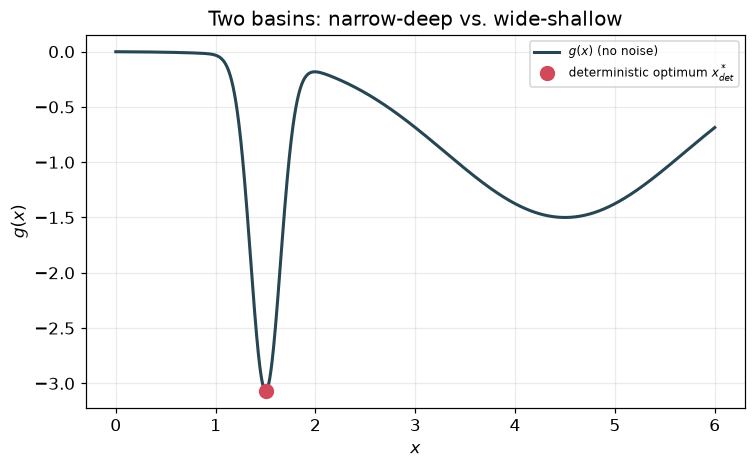

deterministic optimum: x_det = 1.5010,  g(x_det) = -3.0660


In [2]:
def g(x):
    return (-3.0 * np.exp(-(x - 1.5) ** 2 / (2 * 0.15 ** 2))
            - 1.5 * np.exp(-(x - 4.5) ** 2 / (2 * 1.2 ** 2)))

x_dense = np.linspace(0, 6, 2000)
x0_global = x_dense[np.argmin(g(x_dense))]  # coarse grid search first: a purely local method could
res_det = minimize_scalar(g, bounds=(x0_global - 0.3, x0_global + 0.3), method="bounded")  # easily miss the narrow basin
x_det = res_det.x

fig, ax = plt.subplots(figsize=(7, 4.4))
ax.plot(x_dense, g(x_dense), color=COLORS["nominal"], lw=2, label="$g(x)$ (no noise)")
ax.plot(x_det, g(x_det), "o", color=COLORS["det"], ms=9, label="deterministic optimum $x^*_{det}$")
ax.set(xlabel="$x$", ylabel="$g(x)$", title="Two basins: narrow-deep vs. wide-shallow")
ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

print(f"deterministic optimum: x_det = {x_det:.4f},  g(x_det) = {g(x_det):.4f}")

As expected, the deterministic optimizer finds the deep narrow dip -- it is the
best point *if manufactured exactly*, promising $g\approx-3$. The next section
asks what that promise is actually worth once it is not manufactured exactly.

---
## 2. Propagating manufacturing noise: mean and std vs. nominal $x$

Model the as-built value as $X=x_{\text{nominal}}+Z$, $Z\sim\mathcal
N(0,\sigma_z^2)$, and sweep $x_{\text{nominal}}$ over the domain. To keep the
curves smooth without needing a huge sample at every point, the *same* noise
draws $Z$ are reused at every nominal $x$ (a common-random-numbers variance
reduction trick) -- only the shift changes.

> **Predict:** will $\mathbb E[g(X)]$ still bottom out near $x=1.5$, or will
> $\mathbb E[g(X)]$'s minimizer move all the way over to the broad basin?

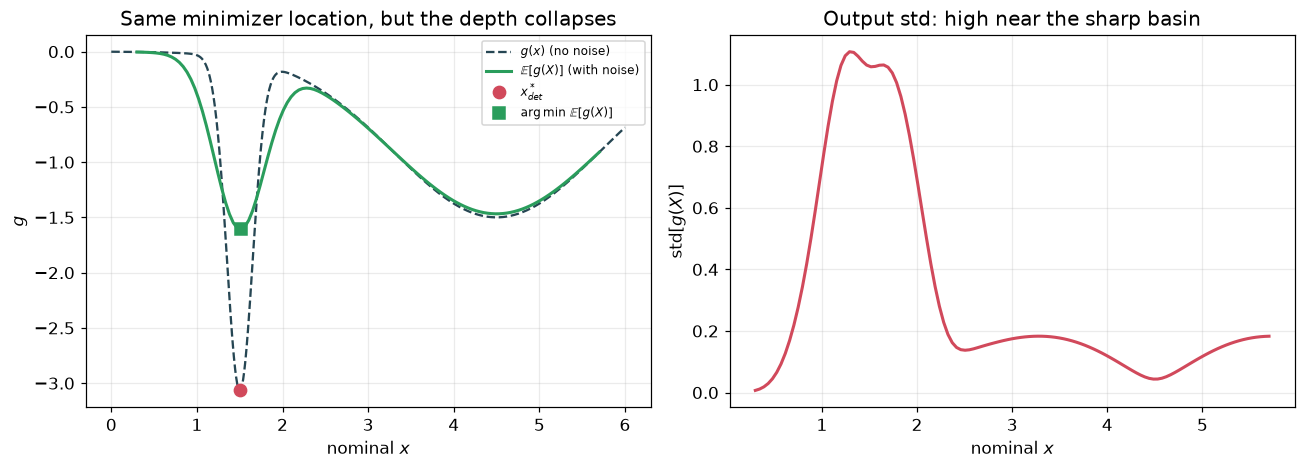

noise-free optimum:        x_det      = 1.5010,        g(x_det)  = -3.0660
minimizer of E[g(X)]:      x_rob_mean = 1.5150,   E[g] here = -1.6072
std[g(X)] at x_det:        1.0580
std[g(X)] at x_rob_mean:   1.0580


In [3]:
sigma_z = 0.25
Z = rng.normal(0.0, sigma_z, 20_000)  # fixed draws, reused (common random numbers) for every x below

x_grid = np.linspace(0.3, 5.7, 121)
mean_g = np.array([g(x + Z).mean() for x in x_grid])
std_g = np.array([g(x + Z).std(ddof=1) for x in x_grid])

x_rob_mean = x_grid[np.argmin(mean_g)]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
axes[0].plot(x_dense, g(x_dense), color=COLORS["nominal"], lw=1.5, ls="--", label="$g(x)$ (no noise)")
axes[0].plot(x_grid, mean_g, color=COLORS["mean"], lw=2, label=r"$\mathbb{E}[g(X)]$ (with noise)")
axes[0].plot(x_det, g(x_det), "o", color=COLORS["det"], ms=8, label="$x^*_{det}$")
axes[0].plot(x_rob_mean, mean_g.min(), "s", color=COLORS["mean"], ms=8, label=r"$\arg\min\,\mathbb{E}[g(X)]$")
axes[0].set(xlabel="nominal $x$", ylabel="$g$", title="Same minimizer location, but the depth collapses")
axes[0].legend(fontsize=8)

axes[1].plot(x_grid, std_g, color=COLORS["std"], lw=2)
axes[1].set(xlabel="nominal $x$", ylabel=r"$\mathrm{std}[g(X)]$", title="Output std: high near the sharp basin")
plt.tight_layout(); plt.show()

print(f"noise-free optimum:        x_det      = {x_det:.4f},        g(x_det)  = {g(x_det):.4f}")
print(f"minimizer of E[g(X)]:      x_rob_mean = {x_rob_mean:.4f},   E[g] here = {mean_g.min():.4f}")
print(f"std[g(X)] at x_det:        {std_g[np.argmin(np.abs(x_grid - x_det))]:.4f}")
print(f"std[g(X)] at x_rob_mean:   {std_g[np.argmin(np.abs(x_grid - x_rob_mean))]:.4f}")

$\mathbb E[g(X)]$'s minimizer barely moves from $x_{det}$ -- the narrow basin is
still the best choice *in expectation* too. But look at the *value*: the
noise-free promise of $g\approx-3$ collapses to an expected value barely better
than $-1.6$ once realistic noise is folded in -- averaging over $Z$ smooths away
most of a feature that is narrower than the noise itself. Meanwhile the
$\mathrm{std}[g(X)]$ panel shows the numeric version of the Taguchi
flat-vs-steep picture: variability is huge right where $g$ is sharply curved,
and tiny over the broad basin. Picking $x$ by mean alone is not enough to notice
this -- Section 3 puts a price on it explicitly.

---
## 3. Mean-variance trade-off: a weighted-sum robust objective

$$
\min_x\; w\,\mathbb E[g(X)] + (1-w)\,\mathrm{std}[g(X)]
$$

Sweeping $w\in[0,1]$ traces a mean-std trade-off front, the numeric analogue of
the bi-objective $(\mu_f,\sigma_f)$ formulation on the slide.

> **Predict:** as $w$ decreases from 1 (mean only) to 0 (std only), will the
> selected $x$ move smoothly from the narrow basin toward the broad one, or jump?

    w        x*      E[g]    std[g]
  1.0     1.515    -1.607     1.058
  0.9     1.515    -1.607     1.058
  0.7     4.485    -1.468     0.044
  0.5     4.485    -1.468     0.044
  0.3     4.485    -1.468     0.044
  0.1     4.485    -1.468     0.044
  0.0     0.300    -0.004     0.007


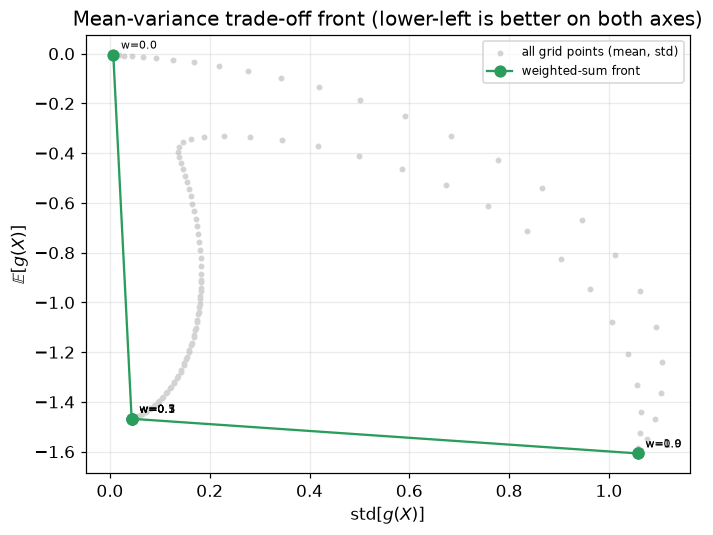

In [4]:
weights = [1.0, 0.9, 0.7, 0.5, 0.3, 0.1, 0.0]
selected = []
for w in weights:
    J = w * mean_g + (1 - w) * std_g
    idx = np.argmin(J)
    selected.append((w, x_grid[idx], mean_g[idx], std_g[idx]))

print(f"{'w':>5}{'x*':>10}{'E[g]':>10}{'std[g]':>10}")
for w, xs, ms, ss in selected:
    print(f"{w:5.1f}{xs:10.3f}{ms:10.3f}{ss:10.3f}")

fig, ax = plt.subplots(figsize=(6.5, 5))
ax.scatter(std_g, mean_g, s=8, color="lightgray", label="all grid points (mean, std)")
sel_arr = np.array([(s, m) for _, _, m, s in selected])
ax.plot(sel_arr[:, 0], sel_arr[:, 1], "o-", color=COLORS["mean"], ms=7, label="weighted-sum front")
for w, xs, ms, ss in selected:
    ax.annotate(f"w={w}", (ss, ms), textcoords="offset points", xytext=(5, 4), fontsize=7)
ax.set(xlabel=r"$\mathrm{std}[g(X)]$", ylabel=r"$\mathbb{E}[g(X)]$",
       title="Mean-variance trade-off front (lower-left is better on both axes)")
ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

It jumps. $w=1.0$ and $w=0.9$ both still pick the narrow basin ($x\approx1.52$)
-- its expected value is genuinely a bit better, so a mean-only or nearly-mean-only
objective keeps choosing the risky option. The instant $w$ drops to $0.7$, the
optimizer jumps all the way to the broad basin ($x\approx4.49$) and stays there
down to $w=0.1$: the narrow basin's huge std is so much larger that almost any
weight on variance outweighs its small mean advantage. The gray scatter shows
why the *selected* points jump instead of sliding: the two basins occupy two
separate arms of the (std, mean) cloud with a gap between them, so this is a
**non-convex** trade-off region -- exactly the situation where weighted-sum
scalarization can jump straight over a whole stretch of intermediate designs
(the middle of $\Omega$ in $x$), the same limitation weighted-sum multiobjective
methods have on a non-convex Pareto front (Ch. 13).

---
## 4. Does robustness actually pay off? A spec-based failure check

Pick $x^*_{det}$ (the deterministic, noise-free optimum from Section 1) and a
robust design $x^*_{rob}$ (the $w=0.5$ point from Section 3), and ask: for a part
manufactured with the same noise $Z$, what is $\Pr\big(g(X) > y_{\text{spec}}\big)$
-- the probability the *as-built* response is worse than a spec limit?

> **Predict:** which design has the higher failure probability against a spec of
> $y_{\text{spec}}=-1.0$: the one with the better *nominal* number, or the one
> with the smaller variance?

In [5]:
x_rob = [xs for w, xs, ms, ss in selected if w == 0.5][0]
y_spec = -1.0
N_check = 500_000
Z_check = rng.normal(0.0, sigma_z, N_check)

g_at_det = g(x_det + Z_check)
g_at_rob = g(x_rob + Z_check)

Pfail_det = np.mean(g_at_det > y_spec)
Pfail_rob = np.mean(g_at_rob > y_spec)

print(f"deterministic design: x = {x_det:.3f},  nominal g = {g(x_det):.3f}")
print(f"  E[g(X)]   = {g_at_det.mean():.3f}   std[g(X)] = {g_at_det.std(ddof=1):.3f}")
print(f"  P(g(X) > {y_spec}) = {Pfail_det:.4f}")
print()
print(f"robust design (w=0.5): x = {x_rob:.3f},  nominal g = {g(x_rob):.3f}")
print(f"  E[g(X)]   = {g_at_rob.mean():.3f}   std[g(X)] = {g_at_rob.std(ddof=1):.3f}")
print(f"  P(g(X) > {y_spec}) = {Pfail_rob:.4f}")

deterministic design: x = 1.501,  nominal g = -3.066
  E[g(X)]   = -1.618   std[g(X)] = 1.058
  P(g(X) > -1.0) = 0.3582

robust design (w=0.5): x = 4.485,  nominal g = -1.500
  E[g(X)]   = -1.468   std[g(X)] = 0.043
  P(g(X) > -1.0) = 0.0000


The deterministic design's nominal number ($g\approx-3.07$) is far better on
paper, yet it fails the spec more than a third of the time once real
manufacturing noise is included -- its own *expected* value is only about
$-1.6$, not much better than the robust design's $-1.47$, and its standard
deviation is roughly 25 times larger. The robust design essentially never
crosses the spec. This is the same lesson as RBDO's reliability index, arrived
at from the objective side instead of the constraint side: the slides present
RBDO and RDO as complementary precisely because one pushes a *constraint* away
from failure while the other reshapes the *objective* to be insensitive to
noise in the first place.

---
## Takeaways

1. A narrow, deep optimum's promised value is not what you actually get: once
   realistic noise is folded in, $\mathbb E[g(X)]$ can collapse toward the level
   of a much broader, shallower alternative, even while the location of the
   best *expected* point barely moves.
2. $\mathrm{std}[g(X)]$ is large near sharply curved regions and small over
   broad, flat ones -- the numeric version of Taguchi's picture, and the piece
   of information that a mean-only comparison completely misses.
3. A weighted-sum mean-variance objective can jump abruptly between two
   basins as the weight changes, rather than sliding smoothly -- a concrete,
   numeric example of weighted-sum scalarization being unable to reach a
   non-convex region of a trade-off (the same limitation it has on non-convex
   Pareto fronts in Ch. 13).
4. A design chosen for robustness can have a dramatically lower failure
   probability against a spec than the "best on paper" deterministic optimum,
   even when the deterministic design's *nominal* number looks much better.

## Classroom exercises

1. Increase $\sigma_z$ further and see whether $\arg\min\mathbb E[g(X)]$
   eventually does jump to the broad basin -- at roughly what $\sigma_z$ does
   that happen?
2. Replace the weighted-sum objective with a hard constraint
   $\mathrm{std}[g(X)]\le\text{budget}$ and find the best mean performance
   subject to it -- the moment-based analogue of $\mu_g+k\sigma_g\le0$ from the
   slide.
3. Sweep $y_{\text{spec}}$ in Section 4 and plot both designs' failure
   probability as a function of the spec -- at what spec value (if any) does the
   deterministic design become the safer choice?